# 04 Stability over time: does the prediction stay accurate and smooth during a discharge?

**Question (REQ-003).** How large is the error of every shape parameter, and does it change during the evolution of the
plasma? Is the output stable from one instant to the next, or does it jump around? Where does the model fail?

The predictions are the out-of-fold ones written by `analysis/ipp1_oof.py` (`out/ipp1-predictions.csv`): every row is
predicted by a network trained on other discharges (5 folds by discharge, 60 epochs). The truth is read back from the
data. The per-decile table and the jitter figures were also saved by `analysis/ipp1_time.py` (`out/ipp1-time.json`);
this notebook recomputes them, checks that they agree, and adds new light analyses (error structure, transitions,
speed of change, a causal smoothing test).

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The data live next to the repository (never inside it): HACKATHON_HOME, else the parent folder of the repository.
here = Path.cwd().resolve()
repo = next(p for p in [here, *here.parents] if (p / "analysis" / "ipp1_common.py").exists())
os.environ.setdefault("HACKATHON_HOME", str(repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import ipp1_common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("raw data folder found:", C.DATA.exists(), "| results folder found:", C.OUT.exists())

raw data folder found: True | results folder found: True


## 1. Load the out-of-fold predictions and score them

In [2]:
df, X, Y, G, M = C.load()
J = {t: i for i, t in enumerate(C.TARGETS)}
pr = pd.read_csv(C.OUT / "ipp1-predictions.csv")
assert np.array_equal(pr.discharge.values, df.discharge.values) and np.allclose(pr.time.values, df.time.values), "rows differ"
P = pr[[f"{t}_pred" for t in C.TARGETS]].values.astype(np.float64)
Y64 = Y.astype(np.float64)
KEY = {}
res = C.score(P, Y, M)
rows = [dict(target=t, unit=res[t]["unit"] or "-", MAE=res[t]["mae"], R2=res[t]["r2"], nRMSE=res[t]["nrmse"]) for t in C.TARGETS]
print("pooled out-of-fold score over all 42972 rows")
print(pd.DataFrame(rows).set_index("target").round(4).to_string())
print("is_limited accuracy:", round(res["is_limited"]["accuracy"], 4))
KEY["pooled_mae"] = {t: round(res[t]["mae"], 5) for t in C.TARGETS}
KEY["is_limited_accuracy"] = round(res["is_limited"]["accuracy"], 4)

pooled out-of-fold score over all 42972 rows
                    unit      MAE      R2   nRMSE
target                                           
plasma_current        kA   1.4877  0.9991  0.0297
R_mag_axis            mm   0.3771  0.9757  0.1559
Z_mag_axis            mm   0.3915  0.9845  0.1246
elongation             -   0.0057  0.9982  0.0429
triangularity          -   0.0028  0.9973  0.0517
triangularity_upper    -   0.0030  0.9931  0.0828
triangularity_lower    -   0.0037  0.9977  0.0477
R_x_point             mm   0.2029  0.9940  0.0774
Z_x_point             mm   0.1954  0.9983  0.0407
R_strike_point_1      mm   0.2648  0.9957  0.0653
Z_strike_point_1      mm   0.1309  0.9933  0.0816
R_strike_point_2      mm   0.2295  0.9977  0.0478
Z_strike_point_2      mm   0.0557  0.9950  0.0705
R_limiter             mm  10.8062  0.8988  0.3181
Z_limiter             mm  22.2510  0.9253  0.2734
is_limited             -   0.0203  0.9792  0.1443
is_limited accuracy: 0.9926


## 2. Error by relative time of the discharge

`time` runs from 0 to 1 in every discharge. We split it into tenths and report the mean absolute error in each tenth.

                    unit   0-10 %  10-20 %  20-30 %  30-40 %  40-50 %  50-60 %  60-70 %  70-80 %  80-90 %  90-100 %
plasma_current        kA   1.2420   1.3341   1.5224   1.2019   1.2363   1.2383   1.3426   1.4977   1.8924    2.3574
R_mag_axis            mm   0.5982   0.2757   0.2853   0.2587   0.2397   0.2360   0.2320   0.2862   0.4462    0.9001
Z_mag_axis            mm   0.4568   0.2611   0.3561   0.2959   0.2943   0.3000   0.2972   0.3331   0.4624    0.8483
elongation             -   0.0045   0.0063   0.0073   0.0052   0.0040   0.0038   0.0040   0.0043   0.0072    0.0101
triangularity          -   0.0024   0.0030   0.0031   0.0022   0.0021   0.0020   0.0020   0.0023   0.0038    0.0054
triangularity_upper    -   0.0021   0.0027   0.0030   0.0027   0.0027   0.0027   0.0028   0.0031   0.0035    0.0045
triangularity_lower    -   0.0034   0.0040   0.0040   0.0026   0.0024   0.0024   0.0024   0.0027   0.0051    0.0077
R_x_point             mm      NaN   0.3222   0.1858   0.1534   0.1486   

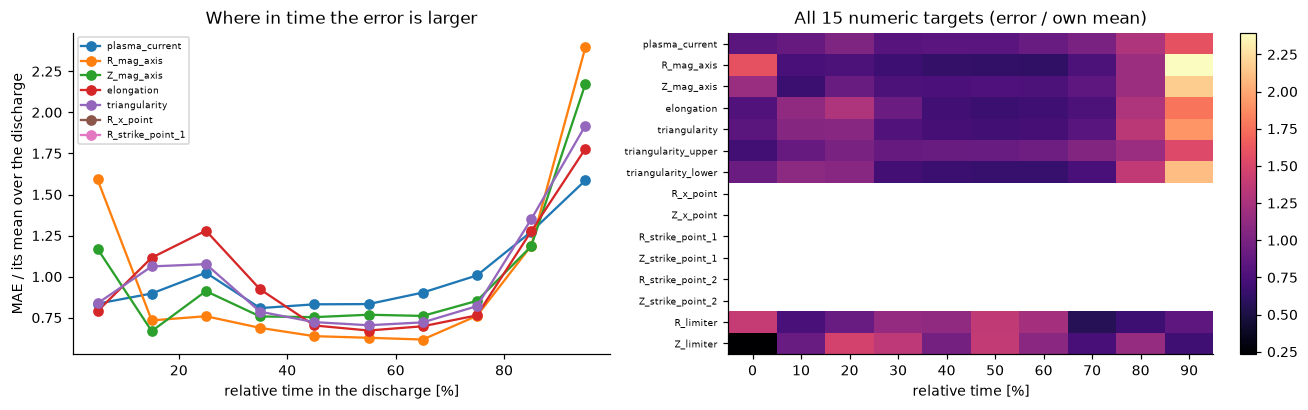

In [3]:
bins = np.minimum((df.time.values * 10).astype(int), 9)
NUM = [t for t in C.TARGETS if t != "is_limited"]
dec = {}
for t in NUM:
    j = J[t]; scale, unit = C.UNIT[t]; k = M[:, j]
    err = np.abs(P[:, j] - Y64[:, j]) * scale
    dec[t] = np.array([err[k & (bins == b)].mean() if (k & (bins == b)).any() else np.nan for b in range(10)])  # NaN: target does not exist in that tenth
dec_tab = pd.DataFrame(dec, index=[f"{b * 10}-{b * 10 + 10} %" for b in range(10)]).T
dec_tab.insert(0, "unit", [C.UNIT[t][1] or "-" for t in NUM])
print(dec_tab.round(4).to_string())

saved_time = json.load(open(C.OUT / "ipp1-time.json"))
rel = [abs(dec[t][b] / saved_time["mae_by_time_decile"][t][b] - 1) for t in saved_time["mae_by_time_decile"] for b in range(10) if not np.isnan(dec[t][b])]
KEY["agreement_with_saved_time_json_max_relative_diff"] = float(max(rel))
print("\nlargest relative difference to out/ipp1-time.json:", f"{max(rel):.2e}")

KEY_T = ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "triangularity", "R_x_point", "R_strike_point_1"]
ends_vs_middle = {t: float(np.nanmean([dec[t][0], dec[t][9]]) / dec[t][2:8].mean()) for t in KEY_T}  # tenths where the target does not exist are skipped
KEY["ends_over_middle_error_ratio"] = {t: round(v, 3) for t, v in ends_vs_middle.items()}
KEY["first_decile_last_decile_middle_mae"] = {t: [None if np.isnan(dec[t][0]) else round(float(dec[t][0]), 4), round(float(dec[t][9]), 4), round(float(dec[t][2:8].mean()), 4)] for t in KEY_T}
print("error in the first and last tenth divided by the mean error of tenths 3 to 8:", KEY["ends_over_middle_error_ratio"])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for t in KEY_T:
    ax[0].plot(np.arange(10) * 10 + 5, dec[t] / dec[t].mean(), marker="o", label=t)
ax[0].set_xlabel("relative time in the discharge [%]"); ax[0].set_ylabel("MAE / its mean over the discharge"); ax[0].legend(fontsize=6)
ax[0].set_title("Where in time the error is larger")
im = ax[1].imshow(np.array([dec[t] / dec[t].mean() for t in NUM]), aspect="auto", cmap="magma")
ax[1].set_yticks(range(len(NUM))); ax[1].set_yticklabels(NUM, fontsize=6); ax[1].set_xticks(range(10)); ax[1].set_xticklabels([f"{b * 10}" for b in range(10)])
ax[1].set_xlabel("relative time [%]"); ax[1].set_title("All 15 numeric targets (error / own mean)"); fig.colorbar(im, ax=ax[1], fraction=0.046)
fig.tight_layout(); plt.show()

## 3. Smoothness from one instant to the next, and whole-discharge offsets

*Jitter ratio* = RMS of the row-to-row change of the prediction divided by the same for the truth (1 means equally smooth;
only pairs of rows closer than 0.01 in relative time are used). *Offset share* = how much of the squared error is a constant
offset of a whole discharge rather than row-to-row noise.

In [4]:
srt = df.sort_values(["discharge", "time"])
idx = srt.index.values
dis, tm = G[idx], df.time.values[idx]
dense = (dis[1:] == dis[:-1]) & (np.diff(tm) < 0.01)
jit, off = {}, {}
for t in KEY_T:
    j = J[t]; k = M[:, j]
    ok = dense & k[idx[1:]] & k[idx[:-1]]
    dp, dt = np.diff(P[idx, j])[ok], np.diff(Y64[idx, j])[ok]
    jit[t] = float(np.sqrt(np.mean(dp ** 2)) / np.sqrt(np.mean(dt ** 2)))
    err = P[:, j] - Y64[:, j]
    per = pd.Series(err[k]).groupby(G[k])
    off[t] = float((per.mean() ** 2 * per.size()).sum() / (err[k] ** 2).sum())
cmp_tab = pd.DataFrame({"jitter_ratio": jit, "offset_share": off, "saved_jitter": {t: saved_time["jitter_ratio"][t] for t in KEY_T}, "saved_offset": {t: saved_time["bias_share"][t] for t in KEY_T}})
print(cmp_tab.round(4).to_string())
KEY["jitter_ratio"] = {t: round(v, 3) for t, v in jit.items()}
KEY["offset_share"] = {t: round(v, 3) for t, v in off.items()}
KEY["jitter_offset_max_abs_diff_to_saved"] = float(max(np.abs(cmp_tab.jitter_ratio - cmp_tab.saved_jitter).max(), np.abs(cmp_tab.offset_share - cmp_tab.saved_offset).max()))
print("share of consecutive row pairs that are dense enough:", round(float(dense.mean()), 3))
KEY["dense_pair_share"] = round(float(dense.mean()), 3)

                  jitter_ratio  offset_share  saved_jitter  saved_offset
plasma_current          1.0734        0.3048        1.0734        0.3048
R_mag_axis              0.9704        0.0958        0.9704        0.0958
Z_mag_axis              1.0630        0.0547        1.0630        0.0547
elongation              1.0303        0.1273        1.0303        0.1273
triangularity           1.0489        0.1371        1.0489        0.1371
R_x_point               0.9995        0.6222        0.9995        0.6222
R_strike_point_1        1.0022        0.8145        1.0022        0.8145
share of consecutive row pairs that are dense enough: 0.994


## 4. Does the error wander slowly or flicker? (autocorrelation of the error inside a discharge)

mean autocorrelation of the error between rows `lag` apart, inside one discharge
             R_mag_axis  elongation  plasma_current
lag 1 rows        0.686       0.807           0.854
lag 2 rows        0.567       0.644           0.756
lag 5 rows        0.321       0.384           0.496
lag 10 rows       0.150       0.161           0.259
lag 20 rows       0.064       0.081           0.091
lag 50 rows      -0.012      -0.054           0.009


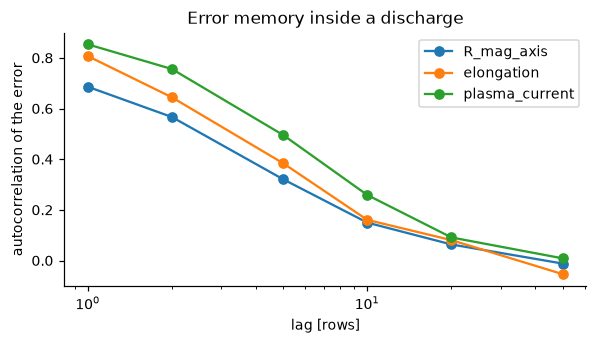

In [5]:
lags = [1, 2, 5, 10, 20, 50]
groups = srt.groupby("discharge").indices
acf = {}
for t in ("R_mag_axis", "elongation", "plasma_current"):
    j = J[t]
    e_sorted = (P[idx, j] - Y64[idx, j])
    acf[t] = []
    for lag in lags:
        cs = []
        for g_, ii in groups.items():
            if len(ii) > lag + 20:
                a, b = e_sorted[ii][:-lag], e_sorted[ii][lag:]
                if a.std() > 0 and b.std() > 0:
                    cs.append(np.corrcoef(a, b)[0, 1])
        acf[t].append(float(np.mean(cs)))
acf_tab = pd.DataFrame(acf, index=[f"lag {l} rows" for l in lags])
print("mean autocorrelation of the error between rows `lag` apart, inside one discharge")
print(acf_tab.round(3).to_string())
KEY["error_autocorrelation"] = {t: {str(l): round(v, 3) for l, v in zip(lags, acf[t])} for t in acf}
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for t in acf:
    ax.plot(lags, acf[t], marker="o", label=t)
ax.set_xscale("log"); ax.set_xlabel("lag [rows]"); ax.set_ylabel("autocorrelation of the error"); ax.legend(); ax.set_title("Error memory inside a discharge")
fig.tight_layout(); plt.show()

## 5. Discharge by discharge: is the model uniformly good?

               unit  median     p90     p95    worst  worst_over_median
target                                                                 
R_mag_axis       mm  0.2359  0.8142  1.4845   6.8027            28.8397
elongation        -  0.0042  0.0104  0.0145   0.0354             8.3456
plasma_current   kA  1.0369  2.6393  3.8872  18.7146            18.0490
worst three discharges for R_mag_axis (id, MAE mm, rows): [(148, 6.8, 44), (127, 4.84, 131), (7, 4.13, 37)]
Spearman between a discharge's R_mag_axis MAE and its number of rows: -0.287


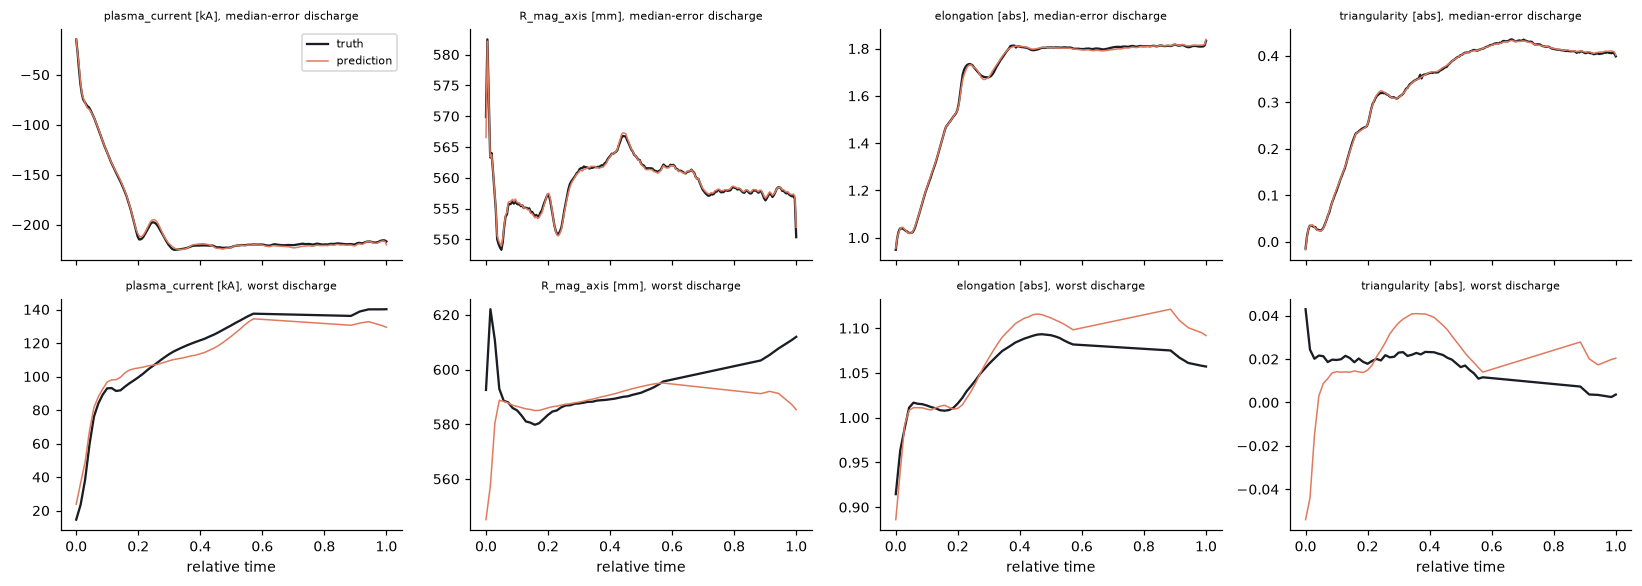

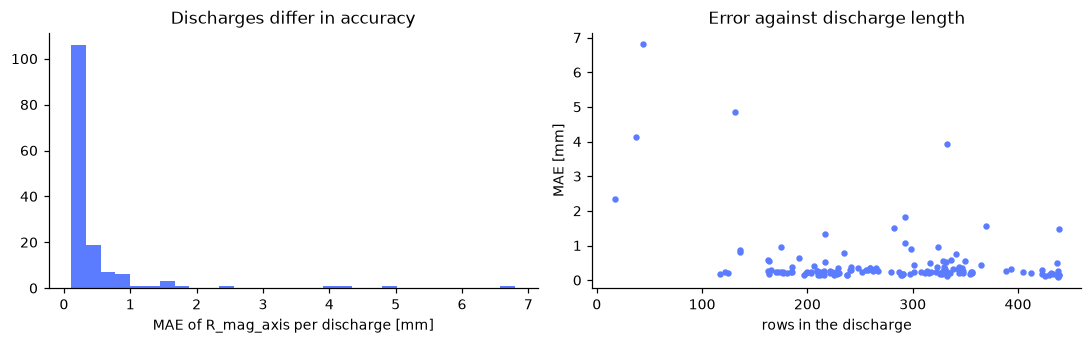

In [6]:
n_rows = df.groupby("discharge").size()
pd_mae = {}
for t in ("R_mag_axis", "elongation", "plasma_current"):
    j = J[t]; scale, unit = C.UNIT[t]
    pd_mae[t] = (pd.Series(np.abs(P[:, j] - Y64[:, j]) * scale).groupby(G).mean())
rows = []
for t, s in pd_mae.items():
    rows.append(dict(target=t, unit=C.UNIT[t][1] or "-", median=s.median(), p90=s.quantile(0.9), p95=s.quantile(0.95), worst=s.max(), worst_over_median=s.max() / s.median()))
print(pd.DataFrame(rows).set_index("target").round(4).to_string())
from scipy.stats import spearmanr
s = pd_mae["R_mag_axis"]
sp = spearmanr(s.values, n_rows.loc[s.index].values)
worst3 = s.sort_values(ascending=False).index[:3]
KEY["per_discharge_mae"] = {t: {"median": round(float(v.median()), 4), "p95": round(float(v.quantile(0.95)), 4), "worst": round(float(v.max()), 4)} for t, v in pd_mae.items()}
KEY["corr_discharge_mae_vs_length_R_mag_axis"] = float(sp.statistic)
KEY["worst3_discharges_R_mag_axis"] = {str(g_): {"mae_mm": round(float(s.loc[g_]), 3), "rows": int(n_rows.loc[g_])} for g_ in worst3}
print("worst three discharges for R_mag_axis (id, MAE mm, rows):", [(int(g_), round(float(s.loc[g_]), 2), int(n_rows.loc[g_])) for g_ in worst3])
print(f"Spearman between a discharge's R_mag_axis MAE and its number of rows: {sp.statistic:.3f}")

med_g = s.index[np.argsort(s.values)[len(s) // 2]]
bad_g = worst3[0]
fig, ax = plt.subplots(2, 4, figsize=(15, 5.4), sharex=True)
for r, (g_, lab) in enumerate(((med_g, "median-error discharge"), (bad_g, "worst discharge"))):
    d = df[df.discharge == g_].sort_values("time")
    for a, t in zip(ax[r], ["plasma_current", "R_mag_axis", "elongation", "triangularity"]):
        j = J[t]; scale, unit = C.UNIT[t]
        a.plot(d.time, d[t] * scale, color="#1a1d23", label="truth")
        a.plot(d.time, P[d.index.values, j] * scale, color="#e07a5f", label="prediction", lw=1)
        a.set_title(f"{t} [{unit or 'abs'}], {lab}", fontsize=7)
ax[0, 0].legend(fontsize=7)
for a in ax[1]:
    a.set_xlabel("relative time")
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(pd_mae["R_mag_axis"].values, bins=30, color="#5b7cff"); ax[0].set_xlabel("MAE of R_mag_axis per discharge [mm]"); ax[0].set_title("Discharges differ in accuracy")
ax[1].scatter(n_rows.loc[s.index].values, s.values, s=10, color="#5b7cff"); ax[1].set_xlabel("rows in the discharge"); ax[1].set_ylabel("MAE [mm]"); ax[1].set_title("Error against discharge length")
fig.tight_layout(); plt.show()

## 6. Is the error concentrated near the switch between limited and divertor plasma?

`is_limited` changes value inside some discharges. For every row we measure its distance (in rows) to the nearest switch
in the same discharge and compare the errors by distance.

In [7]:
lim_sorted = (Y[idx, J["is_limited"]] > 0.5)
dist = np.full(len(idx), 10 ** 6)
n_switch, n_dis_switch = 0, 0
for g_, ii in groups.items():
    ls = lim_sorted[ii]
    sw = np.nonzero(ls[1:] != ls[:-1])[0] + 1
    if len(sw):
        n_switch += len(sw); n_dis_switch += 1
        pos = np.arange(len(ii))
        d_ = np.min(np.abs(pos[:, None] - sw[None, :]), axis=1)
        dist[ii] = d_
KEY["limited_switches"] = {"switches": int(n_switch), "discharges_with_a_switch": int(n_dis_switch)}
print(f"{n_switch} switches of is_limited inside {n_dis_switch} of 149 discharges")
edges_ = [(0, 3), (4, 10), (11, 30), (31, 10 ** 5)]
mis_sorted = ((P[idx, J["is_limited"]] > 0.5) != lim_sorted)
rows = []
for lo, hi in edges_:
    sel = (dist >= lo) & (dist <= hi) & (dist < 10 ** 6) if hi < 10 ** 5 else (dist >= lo)  # last group also holds rows of discharges without a switch
    row = dict(distance_rows=f"{lo}-{hi}" if hi < 10 ** 5 else f">{lo - 1} or no switch", rows=int(sel.sum()), is_limited_wrong_share=float(mis_sorted[sel].mean()))
    for t in ("R_mag_axis", "elongation", "plasma_current"):
        j = J[t]; scale, unit = C.UNIT[t]
        e = np.abs(P[idx, j] - Y64[idx, j]) * scale
        row[f"MAE_{t}"] = float(np.nanmean(e[sel]))
    rows.append(row)
sw_tab = pd.DataFrame(rows).set_index("distance_rows")
print(sw_tab.round(4).to_string())
KEY["error_by_distance_to_switch"] = {i: {k: round(float(v), 4) for k, v in r.items()} for i, r in sw_tab.iterrows()}
KEY["share_of_all_is_limited_errors_within_3_rows_of_a_switch"] = float(mis_sorted[(dist <= 3)].sum() / max(mis_sorted.sum(), 1))
print("share of all misclassified rows that lie within 3 rows of a switch:", round(KEY["share_of_all_is_limited_errors_within_3_rows_of_a_switch"], 3))

456 switches of is_limited inside 137 of 149 discharges
                   rows  is_limited_wrong_share  MAE_R_mag_axis  MAE_elongation  MAE_plasma_current
distance_rows                                                                                      
0-3                1991                  0.1592          0.3976          0.0090              2.1048
4-10               3354                  0.0003          0.3445          0.0072              1.5949
11-30              9343                  0.0000          0.3391          0.0064              1.4496
>30 or no switch  28284                  0.0000          0.3921          0.0050              1.4441
share of all misclassified rows that lie within 3 rows of a switch: 0.994


## 7. Is the error larger where the plasma changes fast?

Speed of change = |change of the true value between two neighbouring rows| / change of relative time. Rows are cut into
four equal-sized groups by speed; the error is the error at the first row of the pair.

In [8]:
same = (dis[1:] == dis[:-1]) & (np.diff(tm) > 0)
speed_tab = {}
KEY["error_by_speed_quartile"] = {}
for t in ("R_mag_axis", "elongation", "plasma_current"):
    j = J[t]; scale, unit = C.UNIT[t]
    ok = same & M[idx[1:], j] & M[idx[:-1], j]
    spd = np.abs(np.diff(Y64[idx, j]))[ok] / np.diff(tm)[ok] * scale
    e = (np.abs(P[idx, j] - Y64[idx, j]) * scale)[:-1][ok]
    q = np.quantile(spd, [0.25, 0.5, 0.75])
    qb = np.digitize(spd, q)
    speed_tab[t] = [float(e[qb == i].mean()) for i in range(4)]
    KEY["error_by_speed_quartile"][t] = [round(v, 4) for v in speed_tab[t]] + [round(float(spearmanr(spd, e).statistic), 3)]
print("MAE in each speed quartile (slowest first), and the Spearman correlation of speed and error (last entry in KEY)")
print(pd.DataFrame(speed_tab, index=["slowest 25 %", "25-50 %", "50-75 %", "fastest 25 %"]).round(4).to_string())
print({t: v[-1] for t, v in KEY["error_by_speed_quartile"].items()})

MAE in each speed quartile (slowest first), and the Spearman correlation of speed and error (last entry in KEY)
              R_mag_axis  elongation  plasma_current
slowest 25 %      0.2784      0.0042          1.3506
25-50 %           0.3008      0.0045          1.2593
50-75 %           0.3216      0.0059          1.7723
fastest 25 %      0.5690      0.0077          1.4822
{'R_mag_axis': 0.144, 'elongation': 0.206, 'plasma_current': 0.165}


## 8. Can a causal smoothing filter remove the jitter without harm?

A real-time controller can only look back in time. We replace each prediction by the mean of the last w predictions of
the same discharge (trailing window) and compare the error with the unfiltered one.

In [9]:
def trailing_mean(x, w):
    c = np.concatenate([[0.0], np.cumsum(x)])
    n = np.arange(1, len(x) + 1)
    lo = np.maximum(0, n - w)
    return (c[n] - c[lo]) / (n - lo)


smooth_tab = {}
KEY["causal_smoothing_mae_ratio"] = {}
for t in ("R_mag_axis", "elongation", "plasma_current"):
    j = J[t]; scale, unit = C.UNIT[t]
    base_err = float(np.nanmean(np.abs(P[idx, j] - Y64[idx, j])) * scale)
    row = {"unfiltered_MAE": base_err}
    for w in (3, 5, 10, 20):
        ps = np.empty(len(idx))
        for g_, ii in groups.items():
            ps[ii] = trailing_mean(P[idx[ii], j], w)
        row[f"w={w}"] = float(np.nanmean(np.abs(ps - Y64[idx, j])) * scale)
    smooth_tab[t] = row
    KEY["causal_smoothing_mae_ratio"][t] = {k: round(v / base_err, 3) for k, v in row.items() if k != "unfiltered_MAE"}
print("MAE after trailing-mean filtering with window w rows (same unit as before)")
print(pd.DataFrame(smooth_tab).T.round(4).to_string())
print("ratio to the unfiltered error:", KEY["causal_smoothing_mae_ratio"])

MAE after trailing-mean filtering with window w rows (same unit as before)
                unfiltered_MAE     w=3     w=5    w=10    w=20
R_mag_axis              0.3771  0.7660  1.1029  1.6708  2.2953
elongation              0.0057  0.0086  0.0130  0.0237  0.0429
plasma_current          1.4877  2.1449  3.1454  5.6232  9.7931
ratio to the unfiltered error: {'R_mag_axis': {'w=3': 2.031, 'w=5': 2.925, 'w=10': 4.431, 'w=20': 6.086}, 'elongation': {'w=3': 1.521, 'w=5': 2.283, 'w=10': 4.167, 'w=20': 7.54}, 'plasma_current': {'w=3': 1.442, 'w=5': 2.114, 'w=10': 3.78, 'w=20': 6.583}}


## 9. Key numbers (read by the conclusions below)

In [10]:
print("KEY_JSON", json.dumps(KEY))

KEY_JSON {"pooled_mae": {"plasma_current": 1.48769, "R_mag_axis": 0.37711, "Z_mag_axis": 0.39146, "elongation": 0.00569, "triangularity": 0.00284, "triangularity_upper": 0.00297, "triangularity_lower": 0.00368, "R_x_point": 0.20292, "Z_x_point": 0.1954, "R_strike_point_1": 0.26477, "Z_strike_point_1": 0.13094, "R_strike_point_2": 0.22952, "Z_strike_point_2": 0.05568, "R_limiter": 10.80617, "Z_limiter": 22.25097, "is_limited": 0.02026}, "is_limited_accuracy": 0.9926, "agreement_with_saved_time_json_max_relative_diff": 2.220446049250313e-16, "ends_over_middle_error_ratio": {"plasma_current": 1.343, "R_mag_axis": 2.923, "Z_mag_axis": 2.086, "elongation": 1.529, "triangularity": 1.711, "R_x_point": 1.797, "R_strike_point_1": 1.548}, "first_decile_last_decile_middle_mae": {"plasma_current": [1.242, 2.3574, 1.3399], "R_mag_axis": [0.5982, 0.9001, 0.2563], "Z_mag_axis": [0.4568, 0.8483, 0.3128], "elongation": [0.0045, 0.0101, 0.0048], "triangularity": [0.0024, 0.0054, 0.0023], "R_x_point": [n

## Conclusions

- **Accuracy on unseen discharges (pooled out-of-fold).** `R_mag_axis` MAE 0.38 mm, `Z_mag_axis` 0.39 mm, plasma current 1.49 kA, elongation 0.0057, `R_x_point` 0.20 mm, `R_strike_point_1` 0.26 mm, the limiter point 10.8 mm and 22.3 mm, and `is_limited` accuracy 99.26 %.
- **The error is larger at the two ends of a discharge.** For `R_mag_axis` the MAE is 0.60 mm in the first tenth and 0.90 mm in the last tenth against 0.26 mm in the middle (tenths 3 to 8), a factor of 2.9; for elongation the factor is 1.5 and for the plasma current 1.3.
- **The output is as smooth as the truth.** The jitter ratio (1 means the same row-to-row change as the truth) is 0.97 for `R_mag_axis`, 1.03 for elongation and 1.07 for the plasma current. The saved table in `out/ipp1-time.json` is reproduced exactly (largest relative difference 2e-16).
- **What the error looks like.** For `R_mag_axis`, only 10 % of the squared error is a constant offset of a whole discharge, but for `R_x_point` it is 62 % and for `R_strike_point_1` 82 %, so for the divertor points the main error is a shift of the whole discharge. The error of `R_mag_axis` is correlated between neighbouring rows (0.69 at lag 1, 0.15 at lag 10) and gone after about 20 rows (0.06), a slow wander and not a flicker.
- **Smoothing in time does not help.** A causal trailing mean of the last 3 predictions raises the error to 2.0 times (`R_mag_axis`), 1.5 times (elongation) and 1.4 times (plasma current); with 20 rows it is 6.1, 7.5 and 6.6 times. The network output has no jitter to remove and the filter mostly adds lag.
- **Discharges differ a lot.** The median `R_mag_axis` MAE per discharge is 0.24 mm, the 95th percentile 1.48 mm and the worst 6.80 mm (discharge 148, 44 rows). Shorter discharges tend to be worse (Spearman -0.29 between error and length).
- **The `is_limited` mistakes sit at the switches.** The plasma switches between limited and divertor 456 times inside 137 of 149 discharges. 99.4 % of the wrongly classified rows lie within 3 rows of a switch, where 15.9 % of the rows are wrong; elongation error is 0.0090 there against 0.0050 far from a switch.
- **Fast changes cost accuracy, for some targets.** The `R_mag_axis` MAE is 0.28 mm in the slowest quarter of rows and 0.57 mm in the fastest (Spearman 0.14); for the plasma current there is no clear trend (1.35 to 1.48 kA).
- **Caveat.** All numbers come from one set of out-of-fold predictions (one training seed per fold).